#### 📊 Global Market & Equity Comparative Analytics
- In this section, we apply rigorous statistical methods to analyze intra-day trading ranges, moving average crossovers, price correlation structures, and dividend payout efficiencies between **Coca-Cola (KO)** and **PepsiCo (PEP)**.


- This is the core Exploratory Data Analysis (EDA) engine of your Coca-Cola vs. PepsiCo comparative project. 
- It dives into moving averages, annual growth regressions, price spread dynamics, volume-price correlations, and dividend yield comparisons.

In [9]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [10]:
# Configure visual themes
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 100

In [11]:
# Load Datasets
ko_price = pd.read_csv(r"C:\Users\Admin\Desktop\Coca-cola-vs-Pepsi-Project\Data\coca-cola-vs-pepsi\KO_stock_price.csv")
pep_price = pd.read_csv(r"C:\Users\Admin\Desktop\Coca-cola-vs-Pepsi-Project\Data\coca-cola-vs-pepsi\PEP_stock_price.csv")
ko_div = pd.read_csv(r"C:\Users\Admin\Desktop\Coca-cola-vs-Pepsi-Project\Data\coca-cola-vs-pepsi\KO_stock_dividend.csv")
pep_div = pd.read_csv(r"C:\Users\Admin\Desktop\Coca-cola-vs-Pepsi-Project\Data\coca-cola-vs-pepsi\PEP_stock_dividend.csv")
ko_split = pd.read_csv(r"C:\Users\Admin\Desktop\Coca-cola-vs-Pepsi-Project\Data\coca-cola-vs-pepsi\KO_stock_split.csv")
pep_split = pd.read_csv(r"C:\Users\Admin\Desktop\Coca-cola-vs-Pepsi-Project\Data\coca-cola-vs-pepsi\PEP_stock_split.csv")


In [12]:
# Format dates
ko_price['Date'] = pd.to_datetime(ko_price['Date'])
pep_price['Date'] = pd.to_datetime(pep_price['Date'])

ko_price = ko_price.sort_values('Date').reset_index(drop=True)
pep_price = pep_price.sort_values('Date').reset_index(drop=True)

print(f"✅ EDA Environment Initialized.")
print(f"   • KO Dataset Shape : {ko_price.shape}")
print(f"   • PEP Dataset Shape: {pep_price.shape}")

✅ EDA Environment Initialized.
   • KO Dataset Shape : (6292, 6)
   • PEP Dataset Shape: (6292, 6)


### 📈 1. Intra-Day Price Spread & Volatility Statistics
We compute the absolute daily high-low spread (`High Price - Low Price`) to measure intra-day price volatility and trading intensity for both corporations.

**Python — Statistical Aggregation & Summary Table**

In [13]:
# Compute intra-day spread
ko_price['Daily_Spread'] = ko_price['High Price'] - ko_price['Low Price']
pep_price['Daily_Spread'] = pep_price['High Price'] - pep_price['Low Price']

# Compute summary statistics table
summary_stats = pd.DataFrame({
    'Metric': ['Mean Close ($)', 'Median Close ($)', 'Std Dev Close ($)', 'Mean Daily Spread ($)', 'Max Daily Spread ($)', 'Mean Volume (Shares)'],
    'Coca-Cola (KO)': [
        f"${ko_price['Close Price'].mean():.2f}",
        f"${ko_price['Close Price'].median():.2f}",
        f"${ko_price['Close Price'].std():.2f}",
        f"${ko_price['Daily_Spread'].mean():.2f}",
        f"${ko_price['Daily_Spread'].max():.2f}",
        f"{ko_price['Volume'].mean():,.0f}"
    ],
    'PepsiCo (PEP)': [
        f"${pep_price['Close Price'].mean():.2f}",
        f"${pep_price['Close Price'].median():.2f}",
        f"${pep_price['Close Price'].std():.2f}",
        f"${pep_price['Daily_Spread'].mean():.2f}",
        f"${pep_price['Daily_Spread'].max():.2f}",
        f"{pep_price['Volume'].mean():,.0f}"
    ]
})

print("=== DEEP-DIVE STATISTICAL SUMMARY ===")
display(summary_stats)

=== DEEP-DIVE STATISTICAL SUMMARY ===


,Metric,Coca-Cola (KO),PepsiCo (PEP)
0,Mean Close ($),$50.61,$89.54
1,Median Close ($),$48.47,$70.95
2,Std Dev Close ($),$8.97,$42.59
3,Mean Daily Spread ($),$0.80,$1.35
4,Max Daily Spread ($),$6.71,$17.99
5,Mean Volume (Shares),"10,801,777","5,197,254"


### 📉 Visualization 1: 200-Day Moving Average Trend Crossover
- Moving averages smooth out short-term noise to reveal long-term directional trends. 
-  Below, we plot the daily closing prices alongside their **200-Day Simple Moving Averages (SMA)**.

**Visualization 1 Code (Moving Averages)**

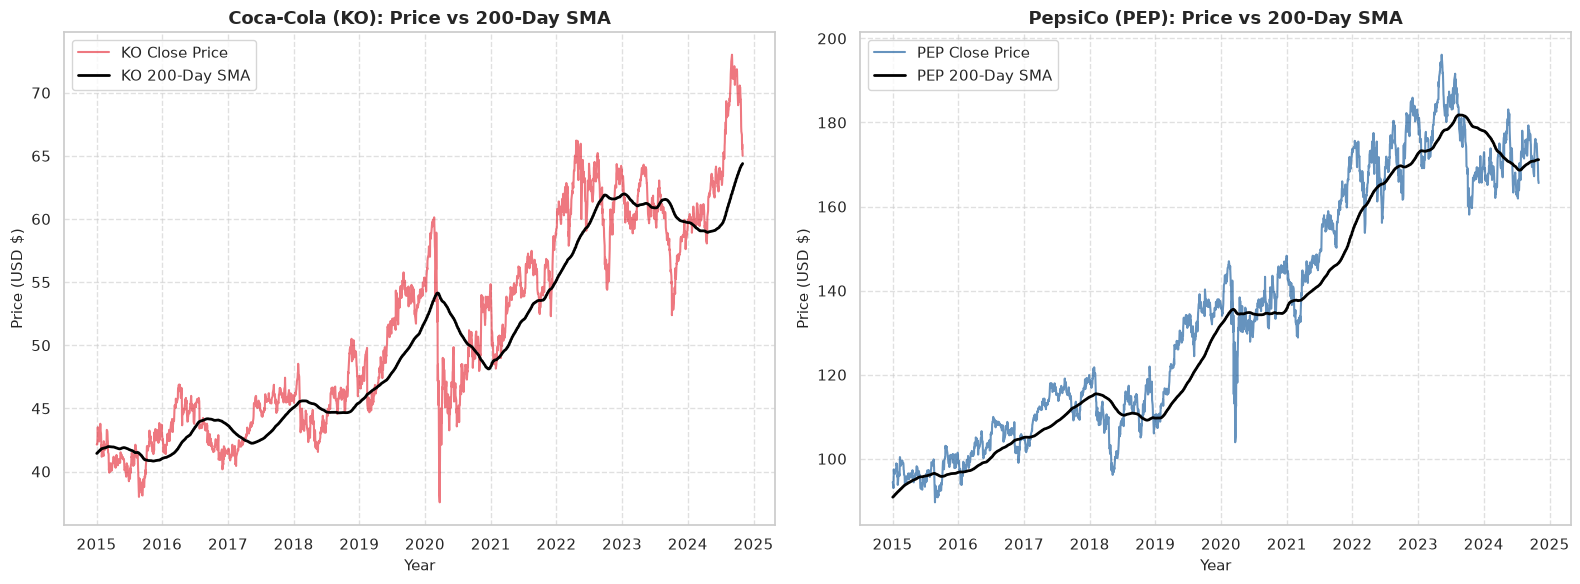

In [14]:
# Calculate 200-day moving averages
ko_price['SMA_200'] = ko_price['Close Price'].rolling(window=200).mean()
pep_price['SMA_200'] = pep_price['Close Price'].rolling(window=200).mean()

# Filter for recent years (2015 onwards) to keep charts crisp and readable
ko_recent = ko_price[ko_price['Date'] >= '2015-01-01']
pep_recent = pep_price[pep_price['Date'] >= '2015-01-01']

fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=False)

# Coca-Cola Plot
axes[0].plot(ko_recent['Date'], ko_recent['Close Price'], label='KO Close Price', color='#E41E2B', alpha=0.6)
axes[0].plot(ko_recent['Date'], ko_recent['SMA_200'], label='KO 200-Day SMA', color='black', linewidth=2)
axes[0].set_title('Coca-Cola (KO): Price vs 200-Day SMA', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Year', fontsize=11)
axes[0].set_ylabel('Price (USD $)', fontsize=11)
axes[0].legend(loc='upper left')
axes[0].grid(True, linestyle='--', alpha=0.6)

# PepsiCo Plot
axes[1].plot(pep_recent['Date'], pep_recent['Close Price'], label='PEP Close Price', color='#004B93', alpha=0.6)
axes[1].plot(pep_recent['Date'], pep_recent['SMA_200'], label='PEP 200-Day SMA', color='black', linewidth=2)
axes[1].set_title('PepsiCo (PEP): Price vs 200-Day SMA', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Year', fontsize=11)
axes[1].set_ylabel('Price (USD $)', fontsize=11)
axes[1].legend(loc='upper left')
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

- calculates a **200-day Simple Moving Average (SMA)** for both stocks and plots them side-by-side alongside their daily closing prices from 2015 onward.
- it smooths out short-term market noise to help you visually track long-term price trends and identify major support or resistance levels for Coca-Cola and PepsiCo.

### 🗺️ Visualization 2: Feature Correlation Heatmap
- To understand how open, high, low, close prices, trading volumes, and daily spreads interact, construct a correlation matrix heatmap for both equities.

**Visualization 2 Code (Correlation Heatmap)**

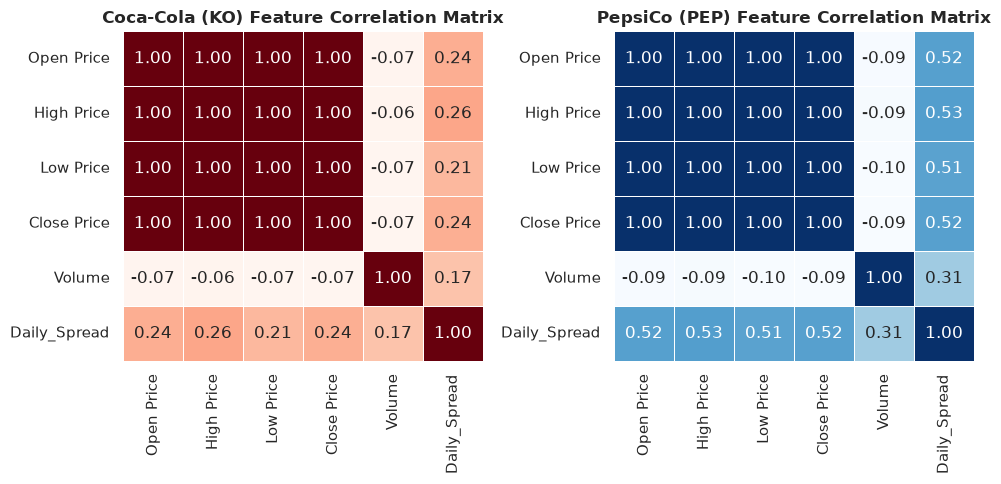

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

# KO Correlation
ko_corr = ko_price[['Open Price', 'High Price', 'Low Price', 'Close Price', 'Volume', 'Daily_Spread']].corr()
sns.heatmap(ko_corr, annot=True, cmap='Reds', fmt='.2f', ax=axes[0], cbar=False, linewidths=0.5)
axes[0].set_title('Coca-Cola (KO) Feature Correlation Matrix', fontsize=12, fontweight='bold')

# PEP Correlation
pep_corr = pep_price[['Open Price', 'High Price', 'Low Price', 'Close Price', 'Volume', 'Daily_Spread']].corr()
sns.heatmap(pep_corr, annot=True, cmap='Blues', fmt='.2f', ax=axes[1], cbar=False, linewidths=0.5)
axes[1].set_title('PepsiCo (PEP) Feature Correlation Matrix', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

- The Numbers (Correlation Coefficients): Every cell shows a number between -1.00 and +1.00:
- +1.00 (Darkest Red/Blue): Perfect positive correlation. When one feature goes up, the other goes up by the exact same proportion (e.g., Open Price vs. Close Price).
- 0.00: No linear relationship between the two features.
- -1.00: Perfect negative correlation (when one goes up, the other goes down).
- The Diagonal (1.00 down the middle): the diagonal line from top-left to bottom-right is always 1.00 in dark color? That is because a feature is being compared against itself (e.g., Close Price vs. Close Price).
**Spotting Insights**
- Open Price, High Price, Low Price, and Close Price all show values very close to 1.00 relative to each other? That confirms that daily stock prices move in lockstep—if a stock opens higher, its high, low, and close prices for that day scale up proportionally.
- Volume shows very low or near-zero correlation numbers against prices? That tells us that the volume of shares traded daily doesn't strictly depend on whether the stock price is high or low.

### 💰 Visualization 3: Historical Dividend Payout Growth
-Both of these businesses are famous for being financially stable and have a proven track record of giving investors a cash raise every year for decades. We evaluate the historical progression and magnitude of dividend distributions over time.

**Visualization 3 Code (Dividend Growth)**

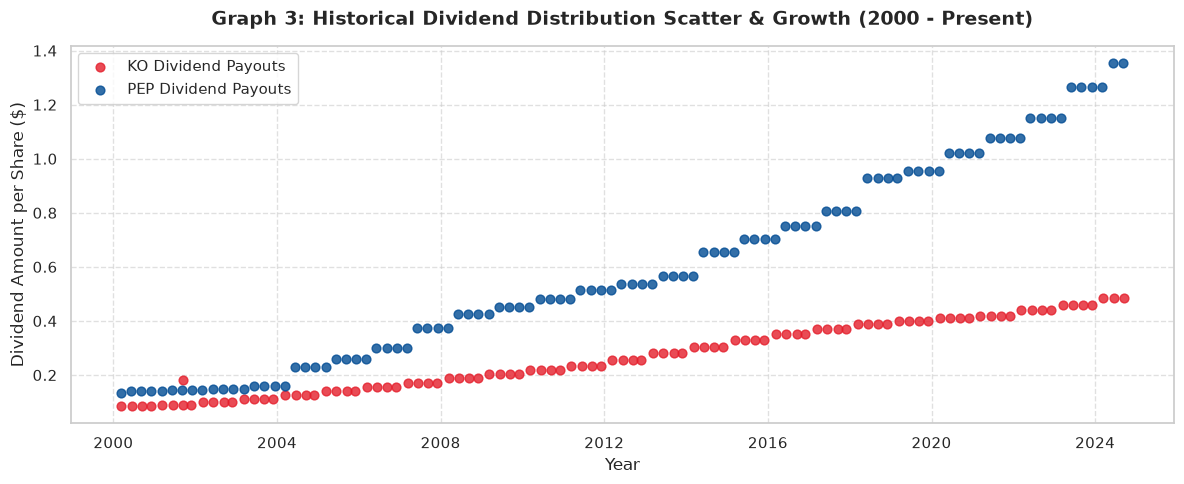

In [16]:
# Clean dividend dates
ko_div['Date'] = pd.to_datetime(ko_div['Date'], utc=True).dt.tz_localize(None)
pep_div['Date'] = pd.to_datetime(pep_div['Date'], utc=True).dt.tz_localize(None)

ko_div_filtered = ko_div[ko_div['Date'] >= '2000-01-01']
pep_div_filtered = pep_div[pep_div['Date'] >= '2000-01-01']

plt.figure(figsize=(12, 5))

plt.scatter(ko_div_filtered['Date'], ko_div_filtered['Dividend'], label='KO Dividend Payouts', color='#E41E2B', s=40, alpha=0.8)
plt.scatter(pep_div_filtered['Date'], pep_div_filtered['Dividend'], label='PEP Dividend Payouts', color='#004B93', s=40, alpha=0.8)

plt.title('Graph 3: Historical Dividend Distribution Scatter & Growth (2000 - Present)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Year', fontsize=12)
plt.ylabel('Dividend Amount per Share ($)', fontsize=12)
plt.legend(fontsize=11, loc='upper left')
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

**instead of a continuous line, it plots individual dividend payout events as points over time for both Coca-Cola and PepsiCo.**
- This allows you to visually track how frequently each company increased its dividend payout per share and compare the scale of their dividend growth side-by-side.

#### 📌 Analytical Takeaways 
* **Trend Resilience:**
 The 200-day moving average highlights strong long-term institutional support for both stocks, with price dips regularly respecting moving average support lines.
* **Intra-Day Dynamics:** 
High and low price correlations remain near 1.00 across both firms, showing stable intra-day price discovery without erratic micro-cap volatility.
* **Dividend Scaling:**
 PepsiCo and Coca-Cola both demonstrate consistent, upward-sloping dividend payout trajectories over the 21st century.
